# 2.5D ink training on PHercParis4
Use all supervised labels for one segment at the selected XY pyramid level.
A nine-layer CT chunk enters a small 3D convolutional stem. Depth max pooling
then feeds a lightweight 2D U-Net that predicts one ink plane.
A contiguous section of the segment is held out for validation; the overview
shows the split, the full annotation footprint and the source rasters.


## Setup
Use a Python kernel with the package's `reader`, `labels` and `torch` dependencies,
Pillow, and the native extensions. No dependencies are installed here.
The first run scans the segment's 2D labels and fetches CT only for supervised
tiles. Source chunks reuse a disk cache capped at 4 GiB. Prepared uint8 patches live in a
temporary directory under that cache, rather than keeping the segment in RAM.

The only imported example helper draws images; discovery, reading, the Dataset,
model, loss and validation are defined below. Set `VC_EXAMPLE_METADATA` to use a
local metadata snapshot, and `VC_EXAMPLE_OFFLINE=1` after caching the inputs.


In [1]:
from pathlib import Path
import os
import sys

# Works when the notebook starts in examples/ or the repository root.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/vc_reader').is_dir())
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'examples')]
# Optional development build; leave unset when using installed extensions.
if os.environ.get('VC_READER_NATIVE_DIR'):
    sys.path.insert(0, str(ROOT / 'benchmarks'))
    from bench_pipeline import load_extensions
    load_extensions(Path(os.environ['VC_READER_NATIVE_DIR']))

import numpy as np
from _display import panel
from vc_reader import load
from vc_reader.reader import MemoryCache
CACHE = Path(os.environ.get('VC_EXAMPLE_CACHE', '/tmp/vc-reader-notebooks'))
OFFLINE = os.environ.get('VC_EXAMPLE_OFFLINE', '0') == '1'
METADATA = os.environ.get('VC_EXAMPLE_METADATA')  # optional local snapshot
# Bound the shared disk cache explicitly so the full segment survives replay.
options = dict(cache_dir=CACHE, cache_max_bytes=4 << 30, offline=OFFLINE, threads=1,
               memory_cache=MemoryCache(64 << 20))
catalog = load(METADATA) if METADATA else load()


In [2]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(7)
torch.set_num_threads(2)
DEVICE = torch.device(os.environ.get('VC_EXAMPLE_DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu'))
print('Training device:', DEVICE)


Training device: cuda


## 1. Discover the segment's labels and their sources


In [3]:
paris = catalog.samples['PHercParis4']
available = list(paris.labels.filter(artifact_kind='ink-labels'))
print(f"{'segment':16} {'label set':12} {'native volume':16} {'paired Zarr images'}")
for label in available:
    print(f'{label.segment.id:16} {label.label_set:12} {label.volume.id:16} {len(label.images.filter(format="zarr"))}')
print('Available label sets:', sorted({label.label_set for label in available}))


segment          label set    native volume    paired Zarr images
20230702185753   20260918     20260411134726   1
20230929220926   20260918     20260411134726   1
20231007101619   20260918     20260411134726   1
20231012184424   20260918     20260411134726   1
20231016151002   20260918     20260411134726   1
20231031143852   20260918     20260411134726   1
20231106155351   20260918     20260411134726   1
20231210121321   20260918     20260411134726   1
Available label sets: ['20260918']


In [4]:
LABEL_SET = '20260918'
SEGMENT = '20231012184424'
LEVEL = 3
PATCH_YX = (512, 512)
LAYER_RADIUS = 4  # four layers on each side of the middle surface layer
BATCH_SIZE = 2
VALIDATION_FRACTION = .20  # approximate supervised-pixel fraction, in whole tile rows
label = paris.segments[SEGMENT].labels.ink(label_set=LABEL_SET)
image_asset = label.images.zarr()
# Read the stored layer count from the header; XY pyramid levels preserve depth.
with image_asset.open(level=LEVEL, **options) as image_reader:
    layer_count = image_reader.shape[image_reader.axes.index('z')]
middle_layer = layer_count // 2
LAYERS = slice(middle_layer-LAYER_RADIUS, middle_layer+LAYER_RADIUS+1)
if LAYERS.start < 0 or LAYERS.stop > layer_count:
    raise ValueError('The render has too few layers for the requested centered window.')
print(f'CT layers: {layer_count}; middle index: {middle_layer}; '
      f'input layers: {LAYERS.start}–{LAYERS.stop-1} (zero-based)')
print('Sample:', paris.id, '| segment:', SEGMENT, '| label set:', LABEL_SET,
      '| native volume:', label.volume.id)
print('Ink:', label.storage.location)
print('CT:', image_asset.storage.location)
for companion in label.companions:
    print(companion.name + ':', companion.source.storage.location)
creation = label.provenance['artifact'].get('creation_info', {})
origin = creation.get('source', {})
print('Original annotation prefix:', origin.get('prefix', 'not recorded'))
for name, raster in origin.get('rasters', {}).items():
    print('  ', name, '←', raster)
print('Published masks:', [c.name for c in label.companions])
print('Validation mask: generated below as a contiguous section of this segment.')


CT layers: 109; middle index: 54; input layers: 50–58 (zero-based)
Sample: PHercParis4 | segment: 20231012184424 | label set: 20260918 | native volume: 20260411134726
Ink: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/segments/20231012184424/ink-labels/2.4um-volume-20260411134726/20260918/inklabels.zarr/
CT: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/segments/20231012184424/surface-volumes/2.4um-0.22m-78keV-volume-20260411134726.zarr/
supervision: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/segments/20231012184424/ink-labels/2.4um-volume-20260411134726/20260918/supervision.zarr/
Original annotation prefix: s3://philodemos/datasets/ink/ink_030927/phercparis4/w05_4424/
   inklabels ← w05_4424_inklabels.tif
   supervision ← w05_4424_supervision_mask.tif
Published masks: ['supervision']
Validation mask: generated below as a contiguous section of this segment.


## 2. Cover the full label canvas and reserve a validation section
`open_paired` follows the published label → flattened-image relationship and
aligns ink and masks to the selected CT grid. A label-only pass uses an empty
layer slice, so it reads no CT chunks. A non-overlapping 512×512 grid covers the
entire canvas, including partial edge tiles. Every tile with supervised pixels
is retained, including tiles containing only negative labels.

This segment publishes supervision but no validation mask. Reserve the bottom
section of the supervised region: choose the whole-tile-row boundary closest to
20% of supervised pixels, using only supervision coverage. No letters or model
predictions influence the boundary. Tiles never straddle it, so the training and
validation inputs do not overlap. The generated validation mask is `y >= split_y`.

Training support is `valid & supervision & ~validation`; validation support is
`valid & supervision & validation`. Validity includes the label and **every** CT
layer. Nonzero ink is class 1, supervised zero ink is a negative, and unknown
pixels never contribute to loss. All coverage is at stored XY level 3 (8× native
pixel spacing); finer annotations may be lost in the published decimated pyramid.
The input window is centered on the middle stored layer, derived from the render
header. This render has 109 layers: middle index 54, input layers 50–58.
Layer indices alone do not specify physical depth offsets.


In [5]:
from tempfile import TemporaryDirectory
from PIL import Image, ImageDraw, ImageFont

CACHE.mkdir(parents=True, exist_ok=True)
patch_cache = TemporaryDirectory(prefix='ink-25d-', dir=CACHE)
patch_dir = Path(patch_cache.name)
records = []
PREVIEW_STRIDE = 8  # max pooling keeps small annotation regions visible
ph, pw = PATCH_YX
assert ph % PREVIEW_STRIDE == pw % PREVIEW_STRIDE == 0

def thumbnail(values):
    return values.reshape(ph//PREVIEW_STRIDE, PREVIEW_STRIDE,
                          pw//PREVIEW_STRIDE, PREVIEW_STRIDE).any(axis=(1, 3))

with label.open_paired(image=image_asset, level=LEVEL, layers=slice(0, 0),
                       backend='cpu', **options) as reader:
    canvas_yx = reader.shape
    rows, cols = ((n+p-1)//p for n, p in zip(canvas_yx, PATCH_YX))
    overview_shape = (rows*ph//PREVIEW_STRIDE, cols*pw//PREVIEW_STRIDE)
    ink_overview = np.zeros(overview_shape, dtype=bool)
    supervision_overview = np.zeros(overview_shape, dtype=bool)
    row_counts = np.zeros(rows, dtype=np.int64)  # exact pixel counts, not image intensities
    mask_values = set()
    for row in range(rows):
        for col in range(cols):
            start = (row*ph, col*pw)
            sample = reader.read(start, PATCH_YX)
            target = sample.label.data > 0
            mask = sample.label.masks['supervision']
            mask_values.update(np.unique(mask).tolist())
            support = sample.label.valid & (mask > 0)
            y, x = (v//PREVIEW_STRIDE for v in start)
            region = np.s_[y:y+ph//PREVIEW_STRIDE, x:x+pw//PREVIEW_STRIDE]
            ink_overview[region] = thumbnail(target[0] & sample.label.valid[0])
            supervision_overview[region] = thumbnail(support[0])
            count = int(support.sum())
            row_counts[row] += count
            if count:
                path = patch_dir / f'{row:03d}-{col:03d}.npz'
                records.append(dict(start=start, path=path, label_count=count))
        print(f'Label scan: row {row+1}/{rows}, {len(records)} supervised tiles', flush=True)

# Exclude boundaries that would make either split empty.
before = np.cumsum(row_counts)[:-1]
total = int(row_counts.sum())
candidates = np.flatnonzero((before > 0) & (before < total))
if not len(candidates):
    raise ValueError('Supervision must span at least two tile rows; reduce PATCH_YX.')
boundary = candidates[np.argmin(np.abs((total-before[candidates])/total - VALIDATION_FRACTION))]
split_y = int((boundary+1)*ph)
for record in records:
    record['split'] = 'validation' if record['start'][0] >= split_y else 'train'
validation_overview = np.broadcast_to(
    np.arange(overview_shape[0])[:, None]*PREVIEW_STRIDE >= split_y, overview_shape)
print('Canvas YX:', canvas_yx, '| supervision values:', sorted(mask_values))
print('Validation section: level-3 y >=', split_y,
      '| supervised fraction:', float((total-before[boundary])/total))
print('Eligible label pixels:', total, '| tiles:', len(records))


Label scan: row 1/13, 0 supervised tiles
Label scan: row 2/13, 4 supervised tiles
Label scan: row 3/13, 16 supervised tiles
Label scan: row 4/13, 30 supervised tiles
Label scan: row 5/13, 37 supervised tiles
Label scan: row 6/13, 41 supervised tiles
Label scan: row 7/13, 45 supervised tiles
Label scan: row 8/13, 52 supervised tiles
Label scan: row 9/13, 64 supervised tiles
Label scan: row 10/13, 71 supervised tiles
Label scan: row 11/13, 76 supervised tiles
Label scan: row 12/13, 82 supervised tiles
Label scan: row 13/13, 82 supervised tiles
Canvas YX: (6350, 9465) | supervision values: [0, 255]
Validation section: level-3 y >= 4608 | supervised fraction: 0.1704788212265401
Eligible label pixels: 7974187 | tiles: 82


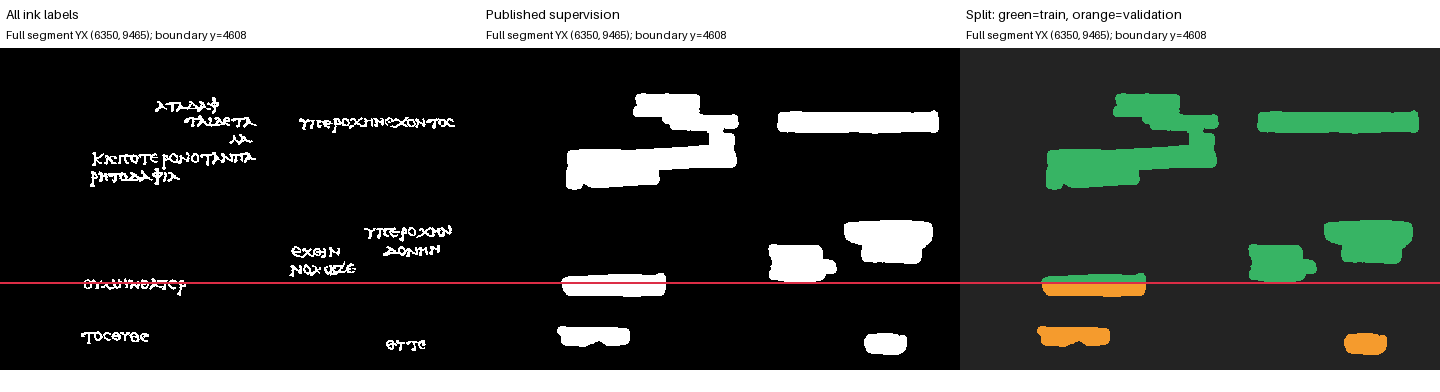

White = ink / supervised; dark = unknown. Red line begins the validation section.
Preview uses max pooling; training uses the original level-3 arrays.


In [6]:
# Show the entire canvas with its aspect ratio preserved, before training.
h, w = ((n+PREVIEW_STRIDE-1)//PREVIEW_STRIDE for n in canvas_yx)
ink_view = ink_overview[:h, :w]
supervision_view = supervision_overview[:h, :w]
validation_view = validation_overview[:h, :w]
coverage = np.full((h, w, 3), 35, dtype=np.uint8)
coverage[supervision_view & ~validation_view] = (55, 180, 100)
coverage[supervision_view & validation_view] = (245, 155, 45)
views = [('All ink labels', np.repeat((ink_view*255).astype(np.uint8)[..., None], 3, axis=2)),
         ('Published supervision', np.repeat((supervision_view*255).astype(np.uint8)[..., None], 3, axis=2)),
         ('Split: green=train, orange=validation', coverage)]
scale = min(480/w, 420/h)
tile_size = (max(1, round(w*scale)), max(1, round(h*scale)))
figure = Image.new('RGB', (3*tile_size[0], tile_size[1]+70), 'white')
draw = ImageDraw.Draw(figure)
for column, (title, values) in enumerate(views):
    tile = Image.fromarray(values).resize(tile_size, Image.Resampling.NEAREST)
    left = column*tile_size[0]
    figure.paste(tile, (left, 48))
    draw.text((left+6, 6), title, fill='black', font=ImageFont.load_default(size=13))
    line_y = 48+round(split_y/PREVIEW_STRIDE*scale)
    draw.line((left, line_y, left+tile_size[0]-1, line_y), fill=(220, 45, 70), width=2)
    draw.text((left+6, 28), f'Full segment YX {canvas_yx}; boundary y={split_y}',
              fill='black', font=ImageFont.load_default(size=11))
display(figure)
print('White = ink / supervised; dark = unknown. Red line begins the validation section.')
print('Preview uses max pooling; training uses the original level-3 arrays.')


## 3. Volumetric features, depth max pooling and a 2D U-Net
Each batch has shape `(B,1,D,H,W)`: one CT intensity channel and nine depth
slices. Two padded 3×3×3 convolutions learn local features across depth and XY.
The 3D stem uses only four feature channels to limit full-resolution activation
memory. Max pooling over **all depth positions**, independently at each XY
location and feature channel, produces `(B,4,H,W)` features for the 2D U-Net.
XY resolution is preserved through this depth pooling.

Three 2D encoder scales collect context across a letter; skip connections
preserve stroke boundaries. Channels are 12, 24, 48 and 96. GroupNorm works with
small batches, and bilinear upsampling keeps the decoder inexpensive. Output,
target and support stay `(B,1,H,W)`. CT normalization uses the whole input chunk,
never its label or support. All operations run on CPU or CUDA in float32.


In [7]:
# Fetch CT only for eligible tiles, keeping one patch in memory at a time.
# Each file holds uint8 CT and boolean labels/support; conversion happens per batch.
with label.open_paired(image=image_asset, level=LEVEL, layers=LAYERS,
                       backend='cpu', **options) as reader:
    for index, record in enumerate(records):
        sample = reader.read(record['start'], PATCH_YX)
        ct = sample.image.data
        assert ct.dtype == np.uint8
        target = sample.label.data > 0
        supervised = sample.label.valid & (sample.label.masks['supervision'] > 0)
        valid = supervised & sample.image.valid.all(axis=1)
        validation_mask = np.broadcast_to(
            (record['start'][0]+np.arange(ph))[:, None] >= split_y, valid.shape)
        train_support = valid & ~validation_mask
        validation_support = valid & validation_mask
        assert not (train_support & validation_support).any()
        assert np.array_equal(train_support | validation_support, valid)
        support = train_support if record['split'] == 'train' else validation_support
        record['count'] = int(support.sum())
        record['positive'] = int((target & support).sum())
        # Preserve CDHW: depth is a spatial dimension for Conv3d.
        np.savez(record['path'], image=ct, target=target, support=support)
        print(f"CT {index+1}/{len(records)}: {record['split']} YX {record['start']}, "
              f"{record['count']:,} supported pixels", flush=True)

class PatchDataset(Dataset):
    """Disk-backed patches; native readers have already closed."""
    def __init__(self, records, split):
        self.records = [r for r in records if r['split'] == split and r['count']]

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        with np.load(self.records[index]['path']) as patch:
            return dict(image=torch.from_numpy(patch['image'].astype(np.float32)/np.float32(255)),
                        target=torch.from_numpy(patch['target'].astype(np.float32)),
                        support=torch.from_numpy(patch['support']))

train_data = PatchDataset(records, 'train')
validation_data = PatchDataset(records, 'validation')
assert len(train_data) and len(validation_data), 'Both splits need valid CT-supported labels.'
# Notebook-defined classes use the main process. CPU tensors also feed CUDA training.
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(7))
validation_loader = DataLoader(validation_data, batch_size=1, shuffle=False, num_workers=0)
for split, dataset in (('train', train_data), ('validation', validation_data)):
    print(split, '| tiles:', len(dataset), '| supported pixels:', sum(r['count'] for r in dataset.records),
          '| positive pixels:', sum(r['positive'] for r in dataset.records))
print('Pixels excluded for invalid CT:', sum(r['label_count']-r['count'] for r in records))
print('Prepared patch bytes on disk:', sum(r['path'].stat().st_size for r in records))


CT 1/82: train YX (512, 2560), 77 supported pixels
CT 2/82: train YX (512, 3072), 58,652 supported pixels
CT 3/82: train YX (512, 3584), 58,665 supported pixels
CT 4/82: train YX (512, 4096), 26,107 supported pixels
CT 5/82: train YX (1024, 2560), 7,444 supported pixels
CT 6/82: train YX (1024, 3072), 169,023 supported pixels
CT 7/82: train YX (1024, 3584), 251,419 supported pixels
CT 8/82: train YX (1024, 4096), 181,433 supported pixels
CT 9/82: train YX (1024, 4608), 104,260 supported pixels
CT 10/82: train YX (1024, 5632), 71,866 supported pixels
CT 11/82: train YX (1024, 6144), 140,645 supported pixels
CT 12/82: train YX (1024, 6656), 135,518 supported pixels
CT 13/82: train YX (1024, 7168), 140,403 supported pixels
CT 14/82: train YX (1024, 7680), 139,446 supported pixels
CT 15/82: train YX (1024, 8192), 132,303 supported pixels
CT 16/82: train YX (1024, 8704), 91,265 supported pixels
CT 17/82: train YX (1536, 1536), 10,968 supported pixels
CT 18/82: train YX (1536, 2048), 23,807 

In [8]:
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, inputs, outputs):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(inputs, outputs, 3, padding=1, bias=False),
            nn.GroupNorm(4, outputs), nn.SiLU(),
            nn.Conv2d(outputs, outputs, 3, padding=1, bias=False),
            nn.GroupNorm(4, outputs), nn.SiLU(),
        )

    def forward(self, x):
        return self.layers(x)

class InkUNet(nn.Module):
    def __init__(self, inputs=1, width=12, stem_width=4):
        super().__init__()
        self.volume_stem = nn.Sequential(
            nn.Conv3d(inputs, stem_width, 3, padding=1, bias=False),
            nn.GroupNorm(4, stem_width), nn.SiLU(),
            nn.Conv3d(stem_width, stem_width, 3, padding=1, bias=False),
            nn.GroupNorm(4, stem_width), nn.SiLU(),
        )
        self.enc1 = ConvBlock(stem_width, width)
        self.enc2 = ConvBlock(width, width*2)
        self.enc3 = ConvBlock(width*2, width*4)
        self.bottleneck = ConvBlock(width*4, width*8)
        self.dec3 = ConvBlock(width*12, width*4)
        self.dec2 = ConvBlock(width*6, width*2)
        self.dec1 = ConvBlock(width*3, width)
        self.head = nn.Conv2d(width, 1, 1)

    def forward(self, x):
        if x.ndim != 5:
            raise ValueError('Expected CT chunks with shape (B,C,D,H,W).')
        mean = x.mean(dim=(1, 2, 3, 4), keepdim=True)
        std = x.std(dim=(1, 2, 3, 4), keepdim=True, correction=0).clamp_min(.02)
        x = ((x-mean)/std).clamp(-5, 5)
        features = self.volume_stem(x)
        # Pool depth only; keep the complete XY grid for the ink prediction.
        features = F.max_pool3d(features, kernel_size=(features.shape[2], 1, 1)).squeeze(2)
        e1 = self.enc1(features)
        e2 = self.enc2(F.avg_pool2d(e1, 2))
        e3 = self.enc3(F.avg_pool2d(e2, 2))
        z = self.bottleneck(F.avg_pool2d(e3, 2))
        for block, skip in ((self.dec3, e3), (self.dec2, e2), (self.dec1, e1)):
            z = F.interpolate(z, size=skip.shape[-2:], mode='bilinear', align_corners=False)
            z = block(torch.cat((z, skip), dim=1))
        return self.head(z)

model = InkUNet(inputs=1).to(DEVICE)
print('Model input: (B,1,D,H,W); depth:', LAYERS.stop-LAYERS.start,
      '| output: (B,1,H,W)')
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')


Model input: (B,1,D,H,W); depth: 9 | output: (B,1,H,W)
Trainable parameters: 275,513


## 4. Train on every training tile each epoch
`TRAIN_EPOCHS` controls runtime; every epoch visits all training tiles once.
Balanced BCE uses a positive weight computed from **training support only**,
and soft Dice encourages complete strokes. CT, target and support receive the
same random XY flips, on CPU or CUDA. Depth order stays fixed. Validation has no augmentation and never
contributes to the optimizer or class weight. The probability threshold stays 0.5.

At each epoch, evaluate all training and validation support. Report BCE/Dice,
foreground fraction and the all-ink baseline. The final weights are used for the
figures; validation does not select a checkpoint.


In [9]:
import time

TRAIN_EPOCHS = 3
initial_parameters = [p.detach().clone() for p in model.parameters()]
positive = sum(r['positive'] for r in train_data.records)
count = sum(r['count'] for r in train_data.records)
pos_weight = torch.tensor((count-positive)/max(positive, 1), dtype=torch.float32, device=DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
print('Training-only positive weight:', float(pos_weight))

def training_loss(logits, target, support):
    bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=pos_weight, reduction='none')
    probability = logits.sigmoid()
    weight = support.to(probability.dtype)
    dims = (1, 2, 3)
    intersection = (probability*target*weight).sum(dim=dims)
    mass = ((probability+target)*weight).sum(dim=dims)
    dice = 1 - ((2*intersection+1)/(mass+1)).mean()
    return bce[support].mean() + .5*dice

@torch.no_grad()
def evaluate(loader):
    model.eval()
    loss_sum = count = intersection = predicted = positives = 0
    for batch in loader:
        image, target, support = (batch[k].to(DEVICE) for k in ('image', 'target', 'support'))
        logits = model(image)
        loss_sum += F.binary_cross_entropy_with_logits(logits, target, reduction='none')[support].sum().item()
        decision, truth = logits > 0, target > 0
        count += support.sum().item()
        intersection += (decision & truth & support).sum().item()
        predicted += (decision & support).sum().item()
        positives += (truth & support).sum().item()
    return dict(BCE=loss_sum/count, Dice=2*intersection/max(predicted+positives, 1),
                foreground=predicted/count, all_ink_Dice=2*positives/max(count+positives, 1))

train_check = DataLoader(train_data, batch_size=1, shuffle=False, num_workers=0)
baseline_train, baseline_validation = evaluate(train_check), evaluate(validation_loader)
print('Before training:', {'train': baseline_train, 'held_out': baseline_validation})
history = []
started = time.perf_counter()
for epoch in range(1, TRAIN_EPOCHS+1):
    for batch in train_loader:
        image, target, support = (batch[k].to(DEVICE) for k in ('image', 'target', 'support'))
        axes = tuple(axis for axis in (-2, -1) if torch.rand(()).item() < .5)
        if axes:
            image, target, support = (v.flip(axes) for v in (image, target, support))
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = training_loss(model(image), target, support)
        assert torch.isfinite(loss), 'Non-finite training loss'
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.)
        optimizer.step()
    train_metrics, validation_metrics = evaluate(train_check), evaluate(validation_loader)
    history.append((epoch, train_metrics, validation_metrics))
    print(f'Epoch {epoch}/{TRAIN_EPOCHS}: train {train_metrics}; held-out {validation_metrics}', flush=True)
print(f'Training and periodic validation: {time.perf_counter()-started:.1f} seconds')
assert any(not torch.equal(before, after) for before, after in zip(initial_parameters, model.parameters()))


Training-only positive weight: 3.833956480026245
Before training: {'train': {'BCE': 0.6307358543728239, 'Dice': 0.08399227740488929, 'foreground': 0.04354566615221088, 'all_ink_Dice': 0.34282052287373743}, 'held_out': {'BCE': 0.6321230053011613, 'Dice': 0.06607668223761283, 'foreground': 0.033739876271672686, 'all_ink_Dice': 0.3546411916424298}}
Epoch 1/3: train {'BCE': 0.6521467730811934, 'Dice': 0.3760831296679257, 'foreground': 0.412316884807711, 'all_ink_Dice': 0.34282052287373743}; held-out {'BCE': 0.662764333324531, 'Dice': 0.3591884502328637, 'foreground': 0.429357157043761, 'all_ink_Dice': 0.3546411916424298}
Epoch 2/3: train {'BCE': 0.6257386642211796, 'Dice': 0.43888547721540067, 'foreground': 0.40044690984113246, 'all_ink_Dice': 0.34282052287373743}; held-out {'BCE': 0.6460867799044043, 'Dice': 0.420744571310894, 'foreground': 0.4274203158676798, 'all_ink_Dice': 0.3546411916424298}
Epoch 3/3: train {'BCE': 0.5561388169859293, 'Dice': 0.4919455379971394, 'foreground': 0.32510

## 5. Inspect well-supervised ink regions
For each split, consider tiles containing both supervised ink and background.
Keep those with at least 90% of the best available supervised coverage, then
choose the tile with the most pixels in its less common class. This favors
well-covered regions with visible ink strokes and surrounding background.
Selection uses only annotation statistics, never model predictions.

Each row shows the same field of view: central CT layer, ink annotation and raw
predicted probability. Captions report supervised coverage and ink fraction.
Gray annotation pixels are outside the split's loss support. Predictions remain
visible over the full tile. These are qualitative illustrations; all eligible
tiles still contribute to the aggregate training and validation metrics above.


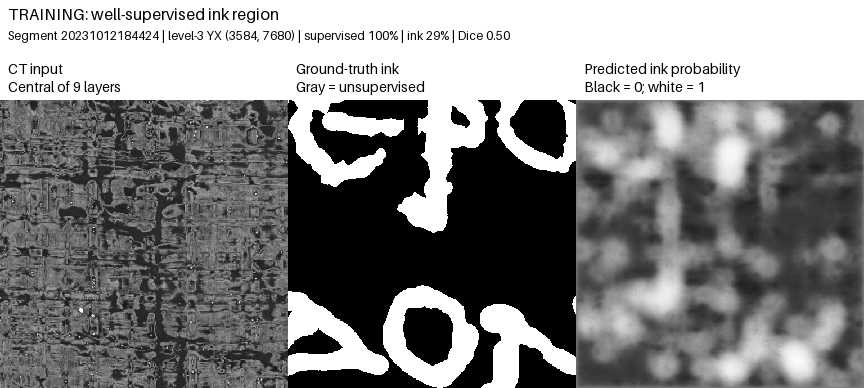

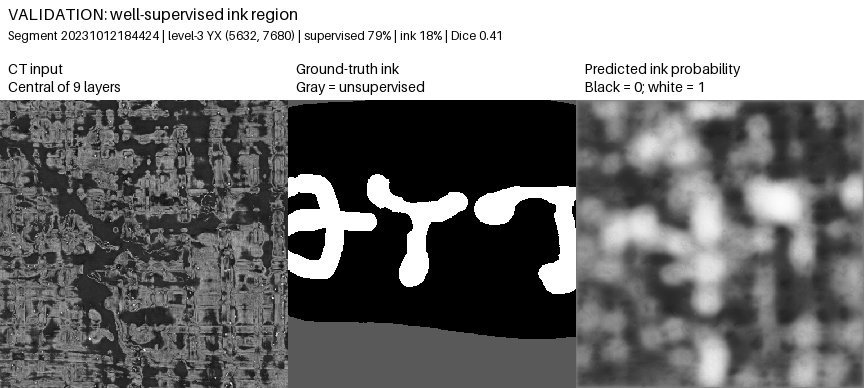

In [10]:
from PIL import Image, ImageDraw, ImageFont

def illustration_index(dataset):
    candidates = [i for i, r in enumerate(dataset.records) if 0 < r['positive'] < r['count']]
    if not candidates:
        raise ValueError('No tile contains both supervised ink and background.')
    best_coverage = max(dataset.records[i]['count'] for i in candidates)
    candidates = [i for i in candidates if dataset.records[i]['count'] >= .9*best_coverage]
    return max(candidates, key=lambda i: (
        min(dataset.records[i]['positive'], dataset.records[i]['count']-dataset.records[i]['positive']),
        dataset.records[i]['count']))

model.eval()
for title, dataset in (
    ('TRAINING: well-supervised ink region', train_data),
    ('VALIDATION: well-supervised ink region', validation_data),
):
    index = illustration_index(dataset)
    record = dataset.records[index]
    p = dataset[index]
    with torch.no_grad():
        probability = model(p['image'][None].to(DEVICE)).sigmoid()[0, 0].cpu().numpy()
    target, support = p['target'][0].numpy(), p['support'][0].numpy()
    decision = probability > .5
    dice = 2*((target > 0) & decision & support).sum()/max(
        ((target > 0) & support).sum()+(decision & support).sum(), 1)
    # Gray marks absent supervision on the label only. Predictions remain unmasked.
    annotation = np.where(support, target, np.float32(.35))
    tiles = panel([(f'CT input\nCentral of {LAYERS.stop-LAYERS.start} layers',
                    p['image'][0, middle_layer-LAYERS.start].numpy()),
                   ('Ground-truth ink\nGray = unsupervised', annotation),
                   ('Predicted ink probability\nBlack = 0; white = 1', probability)], size=288,
                  font_size=14)
    figure = Image.new('RGB', (tiles.width, tiles.height+52), 'white')
    figure.paste(tiles, (0, 52))
    draw = ImageDraw.Draw(figure)
    draw.text((8, 4), title, fill='black', font=ImageFont.load_default(size=16))
    draw.text((8, 28), f"Segment {SEGMENT} | level-{LEVEL} YX {record['start']} | "
              f"supervised {support.mean():.0%} | ink {record['positive']/record['count']:.0%} | Dice {dice:.2f}",
              fill='black', font=ImageFont.load_default(size=12))
    display(figure)


## Interpreting this experiment
All supervised pixels with valid CT at the selected pyramid level contribute to
exactly one split. Entire tile rows are held out, so no input tile crosses the
validation boundary. This measures transfer to a section of the **same segment**;
nearby sheet texture can still be correlated, and it does not establish transfer
to other segments or scrolls. `all_ink_Dice` and foreground fraction help expose
constant predictions. Three epochs are a workflow demonstration, not a claim of
convergence.

The source URLs and original annotation raster names are printed above. The
validation section is generated here, not a published annotation. All native
readers are closed before training. Prepared patches stay on disk while this
kernel holds `patch_cache`; call `patch_cache.cleanup()` when finished with the
Dataset to remove them. Source chunks remain in the reusable disk cache.
